# E4 · Experimento adicional: augmentation moderado en el entrenamiento de E3


## Celda 1 · Configuración de la sesión

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

token = userdata.get('GH_TOKEN')
![ -d /content/yuca_transfer ] || git clone https://{token}@github.com/Frank-Dev007/yuca_transfer.git /content/yuca_transfer
%cd /content/yuca_transfer
!git remote set-url origin https://{token}@github.com/Frank-Dev007/yuca_transfer.git
!git pull
!git config user.name "GhostnzaDevz64"
!git config user.email "tomasgonzalezlopez06@gmail.com"

!python scripts/preparar_datos.py
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
Cloning into '/content/yuca_transfer'...
remote: Enumerating objects: 280, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 280 (delta 17), reused 2 (delta 1), pack-reused 236 (from 1)
Receiving objects: 100% (280/280), 70.34 MiB | 31.43 MiB/s, done.
Resolving deltas: 100% (120/120), done.
/content/yuca_transfer
Already up to date.
Copiando desde Drive...
Tamaño del zip (MB): 1354.1
Contenido de data/: ['cassavaleafdata.zip', 'cassavaleafdata']
name, memory.total [MiB]
Tesla T4, 15360 MiB


## Celda 2 · Verificar que el protocolo y la hipótesis se escribieron antes de E4

In [2]:
!git log -1 --format="protocolo.md · último commit: %ad · %an · %s" --date=iso -- docs/protocolo.md
!git log -1 --format="hipotesis.md · último commit: %ad · %an · %s" --date=iso -- docs/hipotesis.md
!grep -n -i -A3 "15\. Experimento adicional" docs/protocolo.md | head -8

import json, torch
m_e3 = json.load(open("results/E3/metricas.json"))
gpu_actual = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"\nE3 · épocas {m_e3['epocas']} | LR {m_e3['lr']} | batch {m_e3['batch_size']} | semilla {m_e3['semilla']} | "
      f"macro-F1 test {m_e3['test']['macro_f1']:.4f}")
print(f"GPU de E3: {m_e3['gpu']} | GPU actual: {gpu_actual} | {'IGUAL' if m_e3['gpu'] == gpu_actual else 'DISTINTA: anotar en la bitácora'}")

protocolo.md · último commit: 2026-11-19 00:13:11 -0500 · GhostnzaDevz64 · Protocolo: medición del costo computacional (16)
hipotesis.md · último commit: 2026-11-16 13:09:36 -0500 · jdbcamilo · Hipótesis iniciales para experimentos con hojas de yuca
80:### 15. Experimento adicional
81-**Decisión:** se hará sobre E3. El tipo (augmentation moderado en el entrenamiento de E3, o perturbación de brillo sobre una copia del test evaluada con E3) se decidirá después de ejecutar E1 y E3, y su objetivo se declarará aquí antes de ejecutarlo.
82-**Justificación:** el taller permite cualquiera de las dos opciones. Decidir después de tener E3 nos permite elegir la que aporte más al análisis sin retrasar los experimentos principales.
83-

E3 · épocas 10 | LR 0.001 | batch 32 | semilla 42 | macro-F1 test 0.6842
GPU de E3: Tesla T4 | GPU actual: Tesla T4 | IGUAL


## Celda 3 · Preparar


In [3]:
import importlib, os, sys
os.chdir("/content/yuca_transfer")
sys.path.append("/content/yuca_transfer")
importlib.invalidate_caches()

from src.utils import fijar_semilla, obtener_dispositivo
from src.data import crear_dataloaders, transform_modelo, transform_aumentado, MEDIA, DESV
from src.models import crear_modelo
from src.train import ejecutar_experimento

SEED, BATCH, LR, EPOCAS = m_e3["semilla"], m_e3["batch_size"], m_e3["lr"], m_e3["epocas"]   # tomados de E3
fijar_semilla(SEED)
dispositivo = obtener_dispositivo()
loaders_aug = crear_dataloaders(batch_size=BATCH, seed=SEED, transform_train=transform_aumentado)

print(dispositivo, {s: len(l.dataset) for s, l in loaders_aug.items()})
print("\nTransformación de train:\n", loaders_aug["train"].dataset.transform)
print("\nTransformación de validation y test:\n", loaders_aug["test"].dataset.transform)

cuda {'train': 5616, 'validation': 1878, 'test': 1874}

Transformación de train:
 Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    RandomCrop(size=(224, 224), padding=None)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Transformación de validation y test:
 Compose(
    Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## Celda 4 · Comprobar que validation y test NO tienen augmentation

In [4]:
assert loaders_aug["train"].dataset.transform is transform_aumentado, "train no tiene augmentation"
assert loaders_aug["validation"].dataset.transform is transform_modelo, "validation tiene augmentation"
assert loaders_aug["test"].dataset.transform is transform_modelo, "test tiene augmentation"
print("OK: augmentation solo en train; validation y test con el preprocesamiento normal (256 + recorte central 224).")

OK: augmentation solo en train; validation y test con el preprocesamiento normal (256 + recorte central 224).


## Celda 5 · Ver ejemplos de las transformaciones

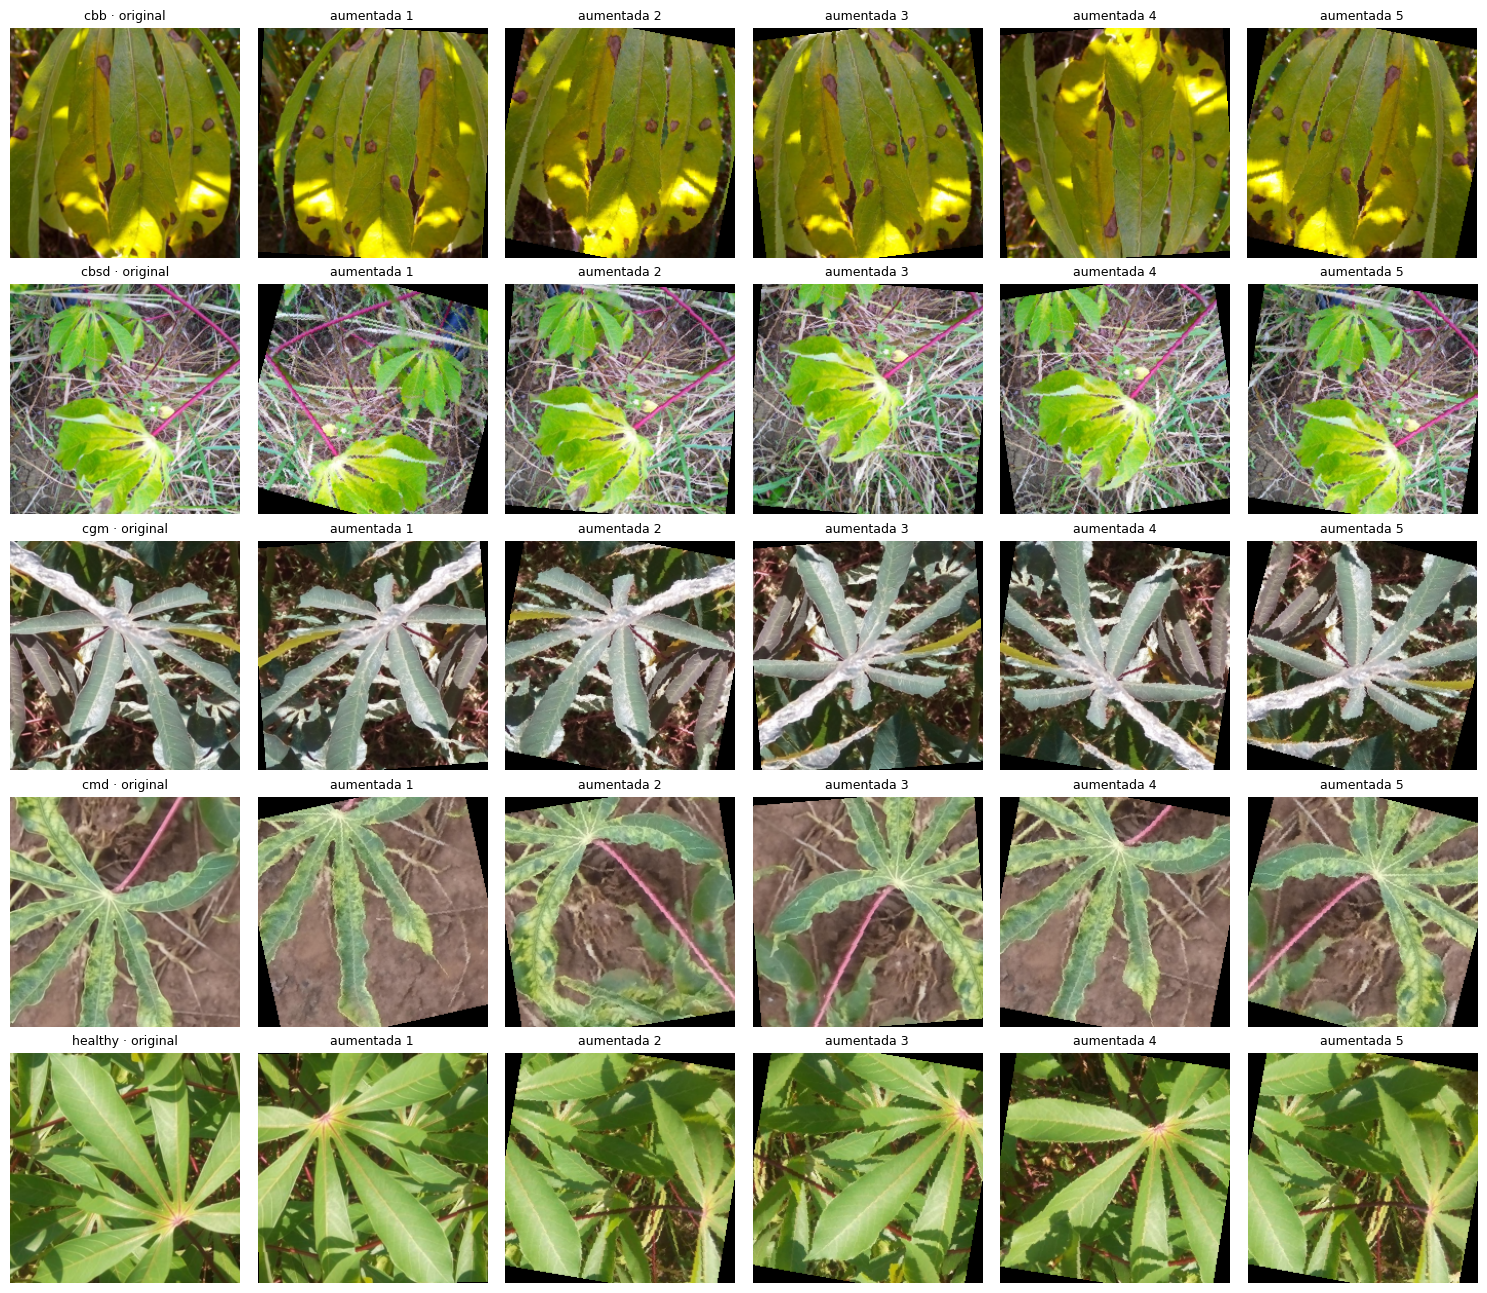

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
from src.data import CLASES

os.makedirs("results/E4", exist_ok=True)
media, desv = torch.tensor(MEDIA).view(3, 1, 1), torch.tensor(DESV).view(3, 1, 1)
def a_imagen(t):                       # deshace la normalización para poder mostrarla
    return (t * desv + media).clamp(0, 1).permute(1, 2, 0).numpy()

tabla_train = loaders_aug["train"].dataset
fig, ejes = plt.subplots(5, 6, figsize=(15, 13))
for fila, clase in enumerate(CLASES):
    i = tabla_train.etiquetas.index(fila)
    img = Image.open(tabla_train.rutas[i]).convert("RGB")
    ejes[fila, 0].imshow(a_imagen(transform_modelo(img))); ejes[fila, 0].set_title(f"{clase} · original", fontsize=9)
    for col in range(1, 6):
        ejes[fila, col].imshow(a_imagen(transform_aumentado(img))); ejes[fila, col].set_title(f"aumentada {col}", fontsize=9)
for e in ejes.flat: e.axis("off")
plt.tight_layout()
plt.savefig("results/E4/ejemplos_augmentation.png", dpi=110)
plt.show()

## Celda 6 · Entrenar E4 (10 épocas, igual que E3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 127MB/s]


Época  1 | pérdida train 1.0856 | pérdida val 0.8835 | macro-F1 val 0.5275 | 55 s
Época  2 | pérdida train 0.8709 | pérdida val 0.8072 | macro-F1 val 0.5083 | 111 s
Época  3 | pérdida train 0.8157 | pérdida val 0.7526 | macro-F1 val 0.5871 | 165 s
Época  4 | pérdida train 0.7860 | pérdida val 0.7462 | macro-F1 val 0.6355 | 217 s
Época  5 | pérdida train 0.7729 | pérdida val 0.7399 | macro-F1 val 0.6342 | 272 s
Época  6 | pérdida train 0.7572 | pérdida val 0.7455 | macro-F1 val 0.6444 | 325 s
Época  7 | pérdida train 0.7540 | pérdida val 0.7777 | macro-F1 val 0.6395 | 380 s
Época  8 | pérdida train 0.7447 | pérdida val 0.7461 | macro-F1 val 0.6359 | 436 s
Época  9 | pérdida train 0.7417 | pérdida val 0.7125 | macro-F1 val 0.6466 | 488 s
Época 10 | pérdida train 0.7285 | pérdida val 0.7362 | macro-F1 val 0.6311 | 544 s


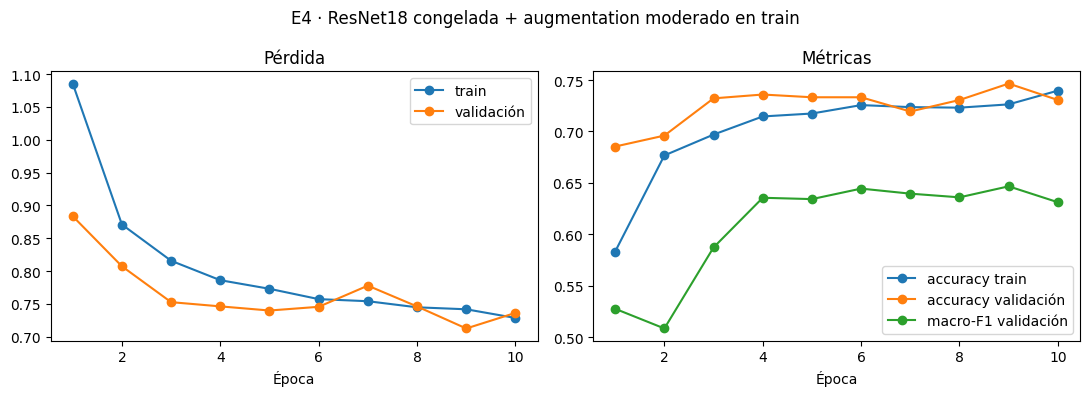

Validación (mejor época): accuracy = 0.7465 | macro-F1 = 0.6466
   cbb      recall = 0.351   F1 = 0.445   (n = 151)
   cbsd     recall = 0.718   F1 = 0.712   (n = 479)
   cgm      recall = 0.623   F1 = 0.643   (n = 257)
   cmd      recall = 0.880   F1 = 0.852   (n = 886)
   healthy  recall = 0.619   F1 = 0.580   (n = 105)

Test: accuracy = 0.7668 | macro-F1 = 0.6577
   cbb      recall = 0.286   F1 = 0.365   (n = 154)
   cbsd     recall = 0.748   F1 = 0.735   (n = 477)
   cgm      recall = 0.648   F1 = 0.664   (n = 253)
   cmd      recall = 0.906   F1 = 0.879   (n = 885)
   healthy  recall = 0.667   F1 = 0.645   (n = 105)


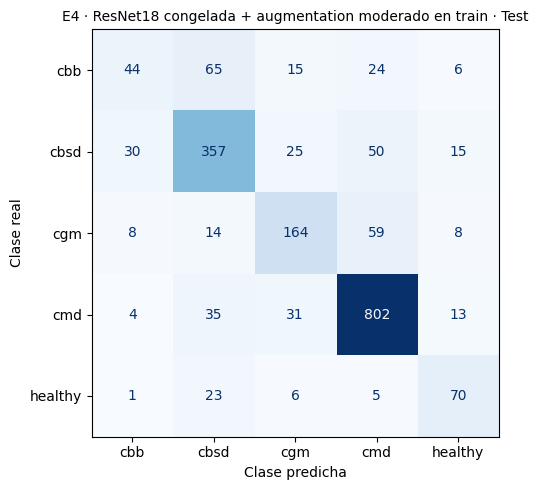


Mejor época: 9 | entrenamiento: 544 s | inferencia: 1.23 ms/imagen | parámetros entrenables: 2,565
Memoria máxima de GPU durante el entrenamiento: 287 MB


In [6]:
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

fijar_semilla(SEED)
modelo = crear_modelo("resnet18")
r_e4 = ejecutar_experimento("E4", modelo, loaders_aug, dispositivo, epocas=EPOCAS, lr=LR, semilla=SEED,
                            descripcion="ResNet18 congelada + augmentation moderado en train",
                            extra={"parte_de": "configuración de E3",
                                   "augmentation": "RandomCrop(224) tras Resize(256), RandomHorizontalFlip, RandomVerticalFlip, RandomRotation(15); solo train"})

mem_entrenamiento_mb = torch.cuda.max_memory_allocated() / 1e6 if torch.cuda.is_available() else None
print(f"Memoria máxima de GPU durante el entrenamiento: {mem_entrenamiento_mb:.0f} MB")

## Celda 7 · Registro de recursos y configuración (igual que en E3)

In [7]:
import platform, datetime, torchvision, sklearn
registro = {
    "experimento": "E4",
    "fecha": datetime.date.today().isoformat(),
    "hardware": {"gpu": gpu_actual, "gpu_igual_a_E3": m_e3["gpu"] == gpu_actual},
    "software": {"python": platform.python_version(), "torch": torch.__version__,
                 "torchvision": torchvision.__version__, "scikit-learn": sklearn.__version__},
    "configuracion": {"backbone": "resnet18 (IMAGENET1K_V1), congelado", "cabeza": "Linear(512, 5)",
                      "epocas": EPOCAS, "lr": LR, "optimizador": "Adam", "batch_size": BATCH, "semilla": SEED,
                      "augmentation_train": str(transform_aumentado),
                      "preprocesamiento_val_test": "Resize(256) + CenterCrop(224) + normalización ImageNet",
                      "seleccion": "mejor macro-F1 en validación", "particiones": "results/particiones_finales.csv"},
    "recursos": {"tiempo_entrenamiento_s": r_e4["tiempo_entrenamiento_s"],
                 "segundos_por_epoca": r_e4["tiempo_entrenamiento_s"] / EPOCAS,
                 "tiempo_inferencia_ms_por_imagen": r_e4["tiempo_inferencia_ms_por_imagen"],
                 "parametros_totales": r_e4["parametros_totales"],
                 "parametros_entrenables": r_e4["parametros_entrenables"],
                 "tamano_checkpoint_mb": r_e4["tamano_checkpoint_mb"],
                 "memoria_gpu_pico_entrenamiento_mb": mem_entrenamiento_mb},
}
json.dump(registro, open("results/E4/config_recursos.json", "w"), indent=2, ensure_ascii=False)
m_e4 = json.load(open("results/E4/metricas.json"))
m_e4["memoria_gpu_pico_entrenamiento_mb"] = mem_entrenamiento_mb
json.dump(m_e4, open("results/E4/metricas.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(registro["recursos"], indent=2, ensure_ascii=False))

{
  "tiempo_entrenamiento_s": 543.9779348373413,
  "segundos_por_epoca": 54.397793483734134,
  "tiempo_inferencia_ms_por_imagen": 1.2256935238838196,
  "parametros_totales": 11179077,
  "parametros_entrenables": 2565,
  "tamano_checkpoint_mb": 44.788363,
  "memoria_gpu_pico_entrenamiento_mb": 286.63296
}


## Celda 8 · Comparación E3 frente a E4 (hechos, sin interpretar)


,Experimento,Accuracy test,Macro-F1 test,Macro-F1 val,Mejor época,Brecha acc. train-val (mejor época),Entrenamiento (s),Inferencia (ms/img)
0,E3 (sin augmentation),0.7727,0.6842,0.6828,10,0.0311,518.1977,1.2311
1,E4 (con augmentation),0.7668,0.6577,0.6466,9,-0.0202,543.9779,1.2257


Diferencia de macro-F1 (E4 - E3): -0.0265 (referencia: variación entre dos ejecuciones de E1 = 0,0078)

Por clase en test:


,recall E3,recall E4,F1 E3,F1 E4,dif. recall,dif. F1
cbb,0.357,0.286,0.425,0.365,-0.071,-0.060
cbsd,0.713,0.748,0.742,0.735,0.035,-0.007
cgm,0.735,0.648,0.674,0.664,-0.087,-0.010
cmd,0.892,0.906,0.877,0.879,0.014,0.002
healthy,0.743,0.667,0.703,0.645,-0.076,-0.058


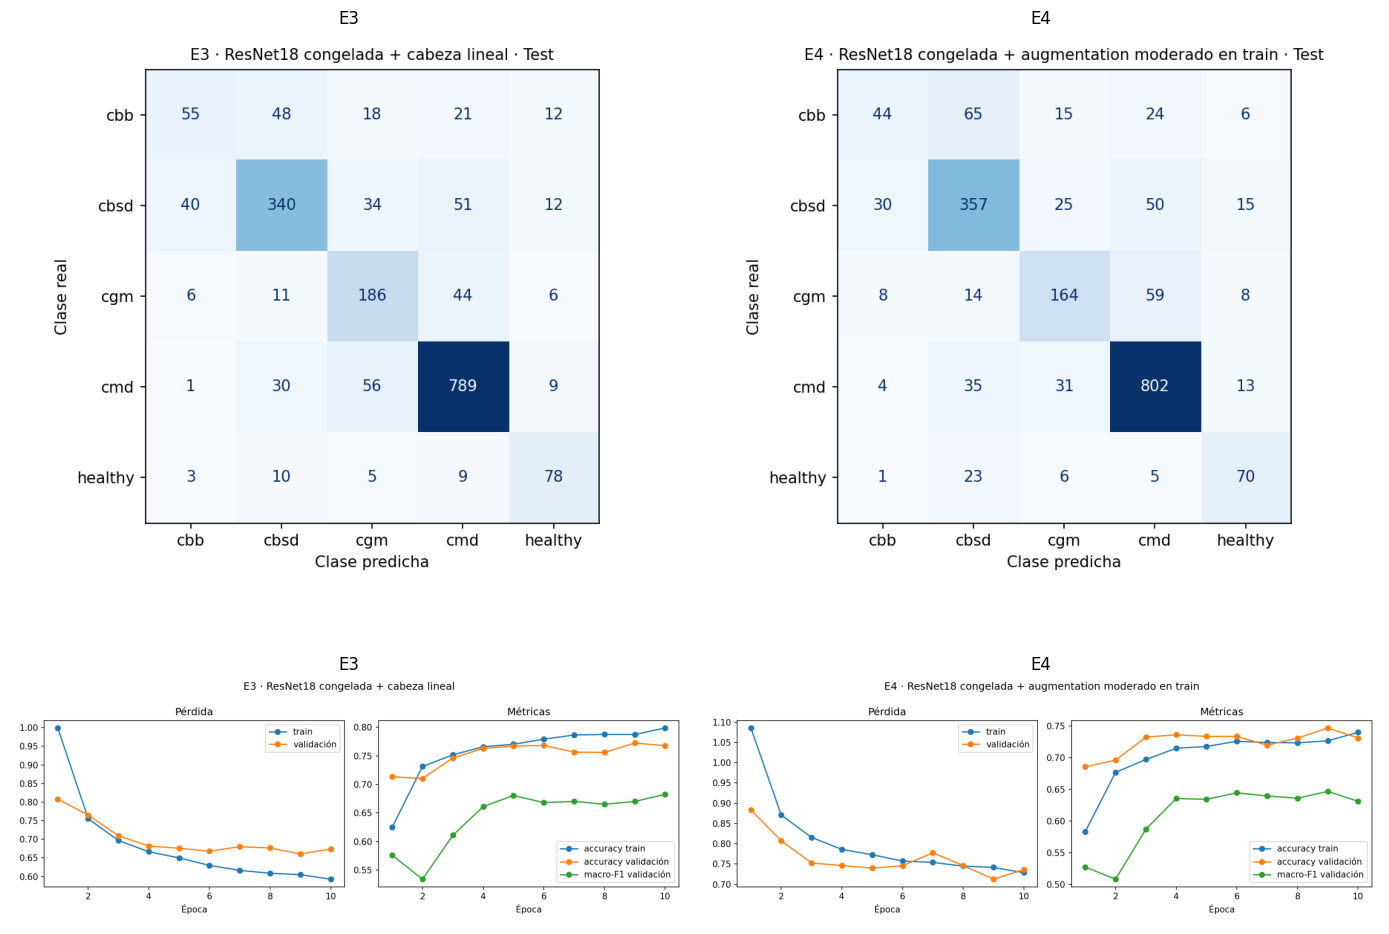

In [8]:
import pandas as pd
from PIL import Image as PILImage

h3, h4 = pd.read_csv("results/E3/historial.csv"), pd.read_csv("results/E4/historial.csv")
def brecha(h, mejor):
    f = h[h.epoca == mejor].iloc[0]
    return f.accuracy_train - f.accuracy_val

tabla = pd.DataFrame([
    {"Experimento": "E3 (sin augmentation)", "Accuracy test": m_e3["test"]["accuracy"], "Macro-F1 test": m_e3["test"]["macro_f1"],
     "Macro-F1 val": m_e3["validacion"]["macro_f1"], "Mejor época": m_e3["mejor_epoca"],
     "Brecha acc. train-val (mejor época)": brecha(h3, m_e3["mejor_epoca"]),
     "Entrenamiento (s)": m_e3["tiempo_entrenamiento_s"], "Inferencia (ms/img)": m_e3["tiempo_inferencia_ms_por_imagen"]},
    {"Experimento": "E4 (con augmentation)", "Accuracy test": m_e4["test"]["accuracy"], "Macro-F1 test": m_e4["test"]["macro_f1"],
     "Macro-F1 val": m_e4["validacion"]["macro_f1"], "Mejor época": m_e4["mejor_epoca"],
     "Brecha acc. train-val (mejor época)": brecha(h4, m_e4["mejor_epoca"]),
     "Entrenamiento (s)": m_e4["tiempo_entrenamiento_s"], "Inferencia (ms/img)": m_e4["tiempo_inferencia_ms_por_imagen"]},
]).round(4)
tabla.to_csv("results/E4/comparacion_E3_E4.csv", index=False)
display(tabla)
print(f"Diferencia de macro-F1 (E4 - E3): {m_e4['test']['macro_f1'] - m_e3['test']['macro_f1']:+.4f} "
      f"(referencia: variación entre dos ejecuciones de E1 = 0,0078)")

por_clase = pd.DataFrame({
    "recall E3": {c: v["recall"] for c, v in m_e3["test"]["por_clase"].items()},
    "recall E4": {c: v["recall"] for c, v in m_e4["test"]["por_clase"].items()},
    "F1 E3": {c: v["f1"] for c, v in m_e3["test"]["por_clase"].items()},
    "F1 E4": {c: v["f1"] for c, v in m_e4["test"]["por_clase"].items()}}).round(3)
por_clase["dif. recall"] = (por_clase["recall E4"] - por_clase["recall E3"]).round(3)
por_clase["dif. F1"] = (por_clase["F1 E4"] - por_clase["F1 E3"]).round(3)
por_clase.to_csv("results/E4/por_clase_E3_E4.csv")
print("\nPor clase en test:"); display(por_clase)

fig, ejes = plt.subplots(2, 2, figsize=(14, 11))
for fila, archivo in enumerate(["matriz_confusion_test.png", "curvas.png"]):
    for col, exp in enumerate(["E3", "E4"]):
        ejes[fila, col].imshow(PILImage.open(f"results/{exp}/{archivo}"))
        ejes[fila, col].set_title(exp); ejes[fila, col].axis("off")
plt.tight_layout()
plt.savefig("results/E4/comparacion_visual_E3_E4.png", dpi=120)
plt.show()

## Celda 9 · Tabla consolidada E0–E4

In [9]:
filas = []
for e in ["E0", "E1", "E2", "E3", "E4"]:
    m = json.load(open(f"results/{e}/metricas.json"))
    entreno = m.get("tiempo_entrenamiento_s", 0)
    if e == "E2":
        entreno += json.load(open("results/E1/metricas.json"))["tiempo_entrenamiento_s"]   # costo E1 + E2
    filas.append({"Experimento": e,
                  "Modelo": m.get("descripcion", m.get("modelo", "")),
                  "Accuracy test": m["test"]["accuracy"],
                  "Macro-F1 test": m["test"]["macro_f1"],
                  "Entrenamiento (s)": entreno,
                  "Inferencia (ms/img)": m.get("tiempo_inferencia_ms_por_imagen", m.get("tiempo_inferencia_clasificador_ms_por_imagen")),
                  "Parámetros totales": m.get("parametros_totales", m.get("parametros")),
                  "Parámetros entrenables": m.get("parametros_entrenables", m.get("parametros"))})
consolidada = pd.DataFrame(filas).round(4)
consolidada.to_csv("results/tabla_consolidada.csv", index=False)
display(consolidada)
print("Nota: E0 reporta solo el tiempo del clasificador; su extracción de histogramas toma unos 9,5 ms por imagen.")

,Experimento,Modelo,Accuracy test,Macro-F1 test,Entrenamiento (s),Inferencia (ms/img),Parámetros totales,Parámetros entrenables
0,E0,Regresión logística sobre histogramas de color...,0.5491,0.2997,2.4533,0.0038,485,485
1,E1,MobileNetV2 congelada + cabeza lineal,0.7689,0.6944,524.0918,1.1450,2230277,6405
2,E2,MobileNetV2 fine-tuning del último bloque (des...,0.8042,0.7323,641.2966,1.2292,2230277,892485
3,E3,ResNet18 congelada + cabeza lineal,0.7727,0.6842,518.1977,1.2311,11179077,2565
4,E4,ResNet18 congelada + augmentation moderado en ...,0.7668,0.6577,543.9779,1.2257,11179077,2565


Nota: E0 reporta solo el tiempo del clasificador; su extracción de histogramas toma unos 9,5 ms por imagen.


## Celda 10 · Subir resultados

In [10]:
!git pull
!git add results/E4 results/tabla_consolidada.csv checkpoints/E4.pt
!git commit -m "E4: augmentation moderado en E3 (ResNet18); comparación E3 vs E4 y tabla consolidada"
!git push

remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 24 (delta 9), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (24/24), 2.91 MiB | 10.10 MiB/s, done.
From https://github.com/Frank-Dev007/yuca_transfer
   3da57bc..c7c5dcb  main       -> origin/main
Updating 3da57bc..c7c5dcb
Fast-forward
 .../30_E4_verificacion_protocolo_hipotesis.png        | Bin 0 -> 76913 bytes
 docs/evidencias/31_E4_val_test_sin_augmentation.png   | Bin 0 -> 51280 bytes
 docs/evidencias/32_E4_ejemplos_augmentation_1.png     | Bin 0 -> 1516774 bytes
 docs/evidencias/33_E4_ejemplos_augmentation_2.png     | Bin 0 -> 941235 bytes
 docs/evidencias/34_E4_entrenamiento_curvas.png        | Bin 0 -> 107163 bytes
 docs/evidencias/35_E4_test_matriz_confusion.png       | Bin 0 -> 52869 bytes
 docs/evidencias/36_E4_resumen_memoria.png             | Bin 0 -> 6554 bytes
 docs/evidencias/37_E4_config_recursos.png    

## Celda 11 · Subir este notebook


In [12]:
%cd /content/yuca_transfer
!cp "/content/drive/MyDrive/Colab Notebooks/06_E4_augmentation.ipynb" notebooks/06_E4_augmentation.ipynb
!git add notebooks/06_E4_augmentation.ipynb
!git commit -m "Notebook E4"
!git push

/content/yuca_transfer
cp: cannot stat '/content/drive/MyDrive/Colab Notebooks/06_E4_augmentation.ipynb': No such file or directory
fatal: pathspec 'notebooks/06_E4_augmentation.ipynb' did not match any files
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date
